# 01 — EDA

In [1]:
import subprocess
import sys
from pathlib import Path

if Path("../src/vod").exists():
    sys.path.insert(0, "../src")
else:
    repo = Path("/kaggle/working/repo")
    if not repo.exists():
        subprocess.run(["git", "clone", "--depth", "1",
                        "https://github.com/mohinska/ai_hw2_MultipleObjectVideoDetection", str(repo)], check=True)
    sys.path.insert(0, str(repo / "src"))

Cloning into '/kaggle/working/repo'...


In [2]:
import random

import cv2
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from matplotlib.patches import Rectangle
from PIL import Image
from sklearn.cluster import KMeans
from sklearn.model_selection import GroupKFold

from vod import CLASSES, SEED
from vod.data import find_data_root, load_coco

DATA = find_data_root()
OUT = Path("/kaggle/working") if Path("/kaggle/working").exists() else Path("../outputs")
EDA_OUT = OUT / "eda"
EDA_OUT.mkdir(parents=True, exist_ok=True)

# everything logged here ends up in eda/eda_summary.md
summary = []


def log(title, obj):
    text = obj.to_string() if hasattr(obj, "to_string") else str(obj)
    summary.append(f"## {title}\n\n```\n{text}\n```\n")
    print(f"\n{title}")
    display(obj)


def savefig(name):
    plt.savefig(EDA_OUT / f"{name}.png", dpi=110, bbox_inches="tight")

## Load annotations

In [3]:
splits, offset = {}, 0
for split in ["train", "val"]:
    images, anns = load_coco(DATA / split)
    images["split"], anns["split"] = split, split
    # ids restart in every split
    images["id"] += offset
    anns["image_id"] += offset
    offset = images["id"].max() + 1
    splits[split] = (images, anns)

images = pd.concat([s[0] for s in splits.values()], ignore_index=True)
anns = pd.concat([s[1] for s in splits.values()], ignore_index=True)
objs = anns[anns["iscrowd"] == 0].copy()
ignore = anns[anns["iscrowd"] == 1].copy()
objs["class"] = objs["cls"].map(dict(enumerate(CLASSES)))
objs["side"] = np.sqrt(objs["area"])

overview = images.groupby("split").agg(clips=("video", "nunique"), frames=("id", "size"))
overview["objects"] = objs.groupby("split").size()
overview["ignored_regions"] = ignore.groupby("split").size()
overview["objects_per_frame"] = (overview["objects"] / overview["frames"]).round(1)
log("Overview", overview)


Overview


,clips,frames,objects,ignored_regions,objects_per_frame
split,,,,,
train,56,24201,1105516,510744,45.7
val,7,2846,114132,31960,40.1


In [4]:
test = pd.read_csv(DATA / "test_images.csv")
res = pd.concat([
    images.groupby(["split", "width", "height"])["video"].nunique().rename("clips"),
    test.assign(split="test").groupby(["split", "width", "height"])["clip"].nunique().rename("clips"),
])
log("Resolutions (clips per size)", res.to_frame())


Resolutions (clips per size)


clips
split width height       
train 1344  756        11
      1360  765         1
      1904  1071       30
      1920  1080        1
      2688  1512       11
      2720  1530        2
val   1344  756         2
      1904  1071        2
      2688  1512        1
      2720  1530        1
      3840  2160        1
test  680   382         3
      960   540         5
      1344  756         7
      1360  764        18
      1904  1072        4
      1920  1080       11

## Data quality

In [5]:
img_cols = ["file_name", "video", "frame_id", "width", "height"]
obj_cols = ["x", "y", "w", "h", "category_id", "occlusion", "truncation", "track_id"]
log("Missing values (count of NaN per column)", pd.concat({
    "images": images.reindex(columns=img_cols).isna().sum(),
    "objects": objs.reindex(columns=obj_cols).isna().sum(),
    "ignored": ignore.reindex(columns=["x", "y", "w", "h"]).isna().sum(),
}))

boxes = objs[["x", "y", "w", "h", "width", "height"]]
log("Box sanity", pd.Series({
    "w or h <= 1 px": ((boxes["w"] <= 1) | (boxes["h"] <= 1)).sum(),
    "x or y < 0": ((boxes["x"] < 0) | (boxes["y"] < 0)).sum(),
    "right/bottom edge outside image": ((boxes["x"] + boxes["w"] > boxes["width"] + 1)
                                        | (boxes["y"] + boxes["h"] > boxes["height"] + 1)).sum(),
    "h/w > 6 or w/h > 6": ((boxes["h"] / boxes["w"] > 6) | (boxes["w"] / boxes["h"] > 6)).sum(),
    "exact duplicate boxes": objs.duplicated(["image_id", "x", "y", "w", "h"]).sum(),
    "same track twice in a frame": objs.dropna(subset=["track_id"]).duplicated(["image_id", "track_id"]).sum(),
}))

n_labels = objs.groupby("image_id").size().reindex(images["id"], fill_value=0)
log("Frames without any object", images.assign(empty=n_labels.to_numpy() == 0)
    .groupby("split")["empty"].agg(["sum", "mean"]).round(3))

gaps = images.sort_values("frame_id").groupby("video")["frame_id"].agg(
    first="min", last="max", frames="size")
gaps["missing_ids"] = gaps["last"] - gaps["first"] + 1 - gaps["frames"]
log("Clips with gaps in frame ids", gaps[gaps["missing_ids"] > 0])

on_disk = pd.Series({clip.name: len(list(clip.glob("*.jpg")))
                     for split in ["train", "val"] for clip in (DATA / split / "images").iterdir()})
in_json = images.groupby("video").size()
log("Clips where jpg count != annotated frames", pd.DataFrame({"jpg": on_disk, "json": in_json})
    .fillna(0).astype(int).loc[lambda d: d["jpg"] != d["json"]])

test_on_disk = sum(1 for _ in (DATA / "test" / "images").rglob("*.jpg"))
log("Test files", f"test_images.csv rows: {len(test)}, jpg on disk: {test_on_disk}, "
                  f"missing values in csv: {int(test.isna().sum().sum())}")


Missing values (count of NaN per column)


images   file_name      0
         video          0
         frame_id       0
         width          0
         height         0
objects  x              0
         y              0
         w              0
         h              0
         category_id    0
         occlusion      0
         truncation     0
         track_id       0
ignored  x              0
         y              0
         w              0
         h              0
dtype: int64


Box sanity


w or h <= 1 px                       0
x or y < 0                           0
right/bottom edge outside image      0
h/w > 6 or w/h > 6                 352
exact duplicate boxes                0
same track twice in a frame          0
dtype: int64


Frames without any object


...

,first,last,frames,missing_ids
video,,,,



Clips where jpg count != annotated frames


,jpg,json



Test files


'test_images.csv rows: 3811, jpg on disk: 3811, missing values in csv: 0'

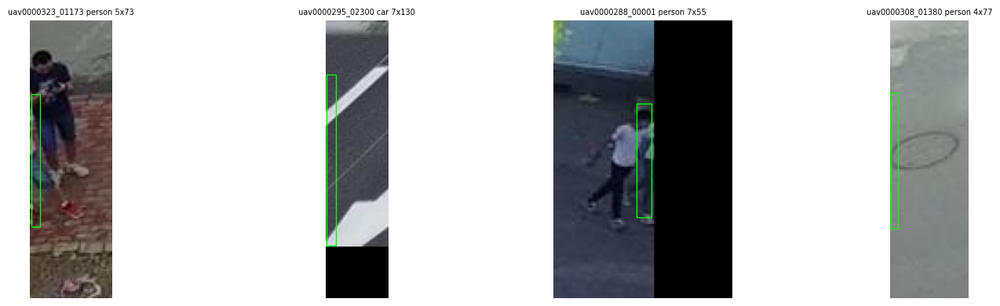

In [6]:
def frame_path(row):
    for base in [DATA / row["split"], DATA, DATA / row["split"] / "images"]:
        if (base / row["file_name"]).exists():
            return base / row["file_name"]
    raise FileNotFoundError(row["file_name"])


image_by_id = images.set_index("id")


def show_crop(ax, a, title, pad=40, color="lime"):
    img = Image.open(frame_path(image_by_id.loc[a["image_id"]]))
    x0, y0 = max(a["x"] - pad, 0), max(a["y"] - pad, 0)
    ax.imshow(img.crop((x0, y0, a["x"] + a["w"] + pad, a["y"] + a["h"] + pad)))
    ax.add_patch(Rectangle((a["x"] - x0, a["y"] - y0), a["w"], a["h"], fill=False, ec=color))
    ax.set_title(title, fontsize=7)
    ax.axis("off")


odd = objs[(objs["h"] / objs["w"] > 6) | (objs["w"] / objs["h"] > 6)]
if len(odd):
    fig, axes = plt.subplots(1, 4, figsize=(16, 4))
    for ax, (_, o) in zip(axes, odd.sample(min(4, len(odd)), random_state=SEED).iterrows()):
        show_crop(ax, o, f"{o['video'][:16]} {o['class']} {o['w']:.0f}x{o['h']:.0f}")
    plt.tight_layout()
    savefig("odd_aspect_boxes")

## Image brightness and contrast

In [7]:
def clip_frames(split, per_clip=5):
    rows = []
    for clip in sorted((DATA / split / "images").iterdir()):
        frames = sorted(clip.glob("*.jpg"))
        for f in frames[::max(1, len(frames) // per_clip)][:per_clip]:
            rows.append({"split": split, "video": clip.name, "path": f})
    return rows


def appearance(path):
    gray = np.asarray(Image.open(path).convert("L").reduce(4), dtype=np.float32)
    return gray.mean(), gray.std(), (gray < 50).mean()


look = pd.DataFrame(clip_frames("train") + clip_frames("val") + clip_frames("test"))
look[["brightness", "contrast", "dark_share"]] = [appearance(p) for p in look["path"]]
log("Brightness / contrast by split",
    look.groupby("split")[["brightness", "contrast", "dark_share"]].describe().round(2).T)


Brightness / contrast by split


split               test   train     val
brightness count  240.00  280.00   35.00
           mean   100.48  116.12  107.57
           std     29.23   25.83   39.85
           min     21.76   40.32   45.01
           25%     79.43  103.65   87.97
           50%    104.79  115.83  104.25
           75%    123.79  128.12  122.33
           max    147.89  187.62  186.28
contrast   count  240.00  280.00   35.00
           mean    41.19   44.35   42.81
           std      9.95   10.48   12.49
           min     17.93   23.31   28.80
           25%     34.40   37.26   33.54
           50%     40.36   43.50   35.56
           75%     47.78   50.65   56.78
           max     70.85   73.50   69.11
dark_share count  240.00  280.00   35.00
           mean     0.20    0.11    0.18
           std      0.23    0.12    0.24
           min      0.00    0.00    0.00
           25%      0.02    0.03    0.02
           50%      0.12    0.08    0.12
           75%      0.30    0.13    0.17
           max      0.94    0.76    0.74

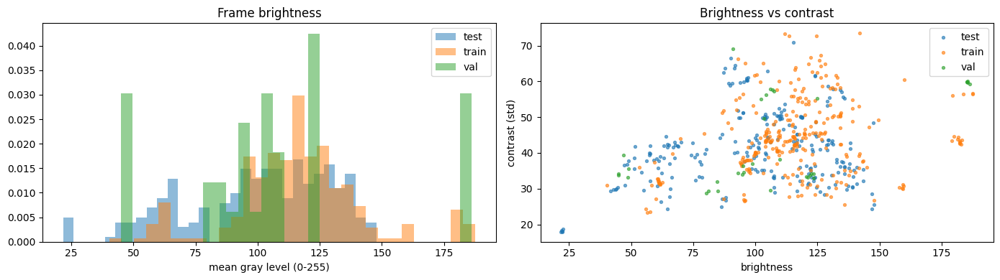

In [8]:
fig, ax = plt.subplots(1, 2, figsize=(14, 4))
for split, g in look.groupby("split"):
    ax[0].hist(g["brightness"], bins=30, alpha=0.5, density=True, label=split)
    ax[1].scatter(g["brightness"], g["contrast"], s=8, alpha=0.6, label=split)
ax[0].set(xlabel="mean gray level (0-255)", title="Frame brightness")
ax[1].set(xlabel="brightness", ylabel="contrast (std)", title="Brightness vs contrast")
ax[0].legend()
ax[1].legend()
plt.tight_layout()
savefig("brightness_hist")

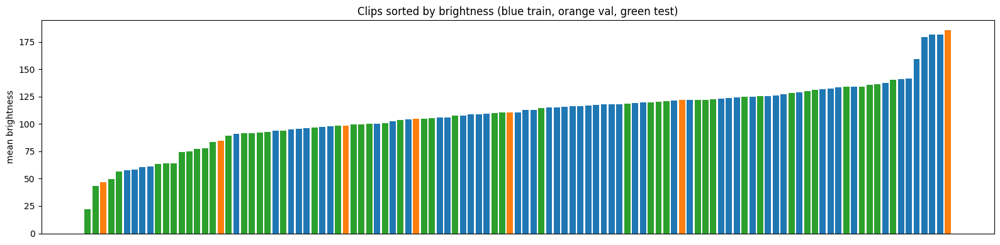

In [9]:
clip_look = look.groupby(["split", "video"])[["brightness", "contrast", "dark_share"]].mean().reset_index()
clip_look = clip_look.sort_values("brightness")
fig, ax = plt.subplots(figsize=(16, 4))
colors = clip_look["split"].map({"train": "tab:blue", "val": "tab:orange", "test": "tab:green"})
ax.bar(range(len(clip_look)), clip_look["brightness"], color=colors)
ax.set(xticks=[], ylabel="mean brightness", title="Clips sorted by brightness (blue train, orange val, green test)")
plt.tight_layout()
savefig("brightness_per_clip")

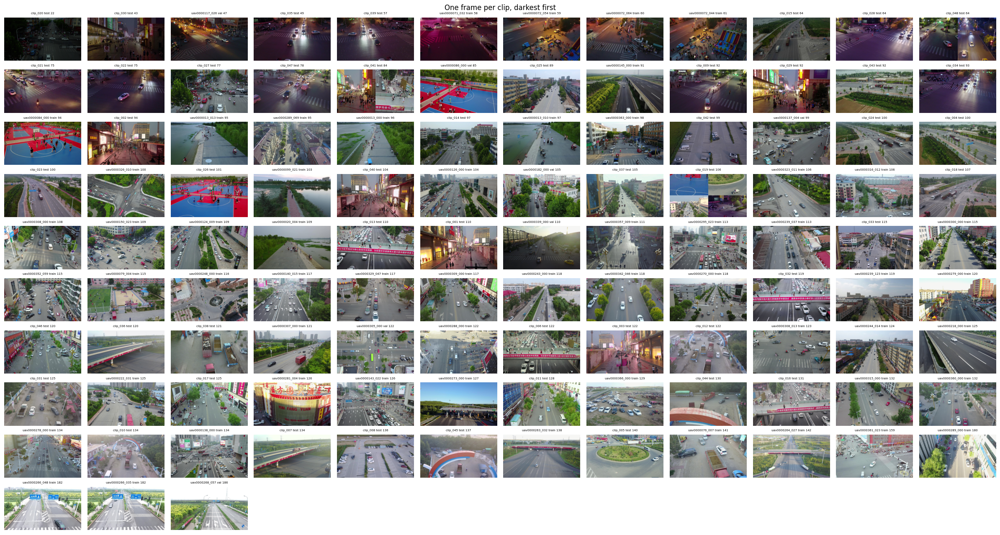

In [10]:
first = look.groupby(["split", "video"]).first().reset_index()
first = first.merge(clip_look[["video", "brightness"]], on="video", suffixes=("_frame", "")).sort_values("brightness")
cols = 12
rows_n = int(np.ceil(len(first) / cols))
fig, axes = plt.subplots(rows_n, cols, figsize=(cols * 2, rows_n * 1.3))
for ax in axes.flat:
    ax.axis("off")
for ax, r in zip(axes.flat, first.itertuples()):
    img = Image.open(r.path)
    img.thumbnail((240, 240))
    ax.imshow(img)
    ax.set_title(f"{r.video[:14]} {r.split} {r.brightness:.0f}", fontsize=5)
plt.suptitle("One frame per clip, darkest first")
plt.tight_layout()
savefig("clip_thumbnails")

## Brightening options on the darkest frames

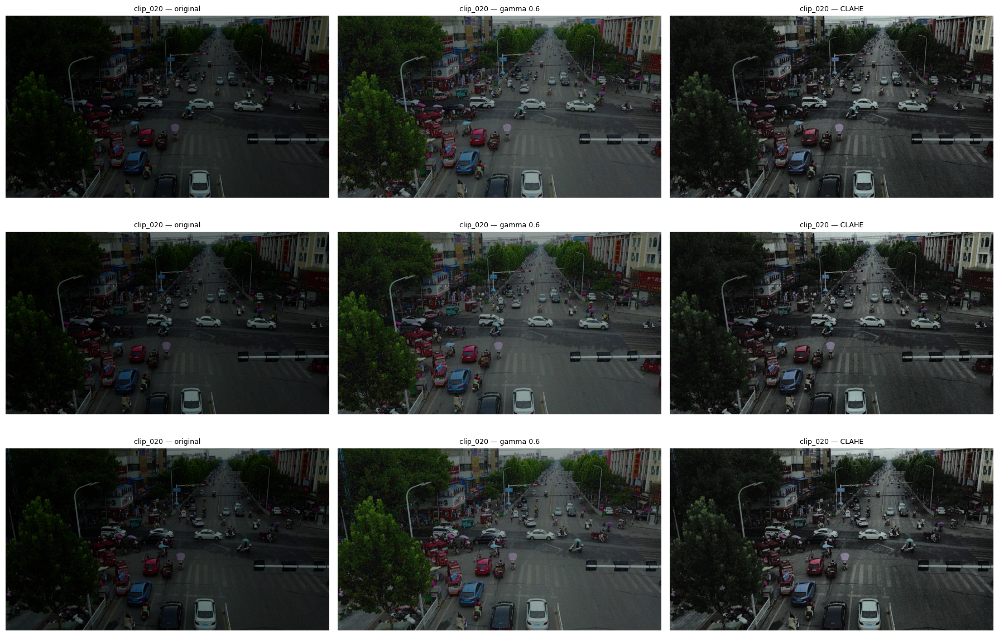

In [11]:
def gamma(img, g=0.6):
    return (255 * (img / 255.0) ** g).astype(np.uint8)


def clahe(img, clip=2.0):
    lab = cv2.cvtColor(img, cv2.COLOR_RGB2LAB)
    lab[..., 0] = cv2.createCLAHE(clipLimit=clip, tileGridSize=(8, 8)).apply(lab[..., 0])
    return cv2.cvtColor(lab, cv2.COLOR_LAB2RGB)


darkest = look.nsmallest(3, "brightness")
fig, axes = plt.subplots(len(darkest), 3, figsize=(18, 4 * len(darkest)))
for row_axes, path in zip(axes, darkest["path"]):
    img = np.asarray(Image.open(path).convert("RGB"))
    for ax, (name, out) in zip(row_axes, [("original", img), ("gamma 0.6", gamma(img)), ("CLAHE", clahe(img))]):
        ax.imshow(out)
        ax.set_title(f"{path.parent.name} — {name}", fontsize=9)
        ax.axis("off")
plt.tight_layout()
savefig("brightening_options")

## Low-resolution test clips

In [12]:
clip_res = pd.concat([images.groupby("video").agg(split=("split", "first"), width=("width", "first"),
                                                  height=("height", "first"), frames=("id", "size")),
                      test.groupby("clip").agg(width=("width", "first"), height=("height", "first"),
                                               frames=("image_id", "size")).assign(split="test")])
log("Frames per clip", clip_res.groupby("split")["frames"].describe().round(0))
low_res = clip_res[clip_res["width"] < 1300].join(clip_look.set_index("video")[["brightness", "contrast"]].round(1))
log("Clips narrower than 1300 px", low_res)


Frames per clip


,count,mean,std,min,25%,50%,75%,max
split,,,,,,,,
test,48.0,79.0,35.0,35.0,49.0,74.0,108.0,148.0
train,56.0,432.0,275.0,58.0,224.0,384.0,550.0,1424.0
val,7.0,407.0,268.0,184.0,254.0,349.0,414.0,978.0



Clips narrower than 1300 px


,split,width,height,frames,brightness,contrast
clip_011,test,680,382,72,128.3,42.8
clip_014,test,960,540,35,96.7,60.6
clip_017,test,680,382,109,125.3,42.6
clip_019,test,960,540,38,105.6,43.8
clip_020,test,960,540,59,22.2,18.2
clip_026,test,960,540,73,101.1,35.2
clip_027,test,960,540,74,77.2,39.7
clip_046,test,680,382,140,119.9,37.2


In [13]:
def sharpness(path, width):
    """Variance of the Laplacian after resizing to a common width: higher = more fine detail."""
    img = Image.open(path).convert("L")
    img = img.resize((width, round(img.height * width / img.width)), Image.BILINEAR)
    return cv2.Laplacian(np.asarray(img), cv2.CV_64F).var()


look["width"] = [Image.open(p).size[0] for p in look["path"]]
look["res_group"] = pd.cut(look["width"], [0, 1000, 1400, 2000, 4000],
                           labels=["680-960", "1344-1360", "1904-1920", "2688-3840"])
look["sharp_680"] = [sharpness(p, 680) for p in look["path"]]
look["sharp_1280"] = [sharpness(p, 1280) for p in look["path"]]
log("Sharpness by split and resolution (680 = same detail level, 1280 = what the network sees)",
    look.groupby(["split", "res_group"], observed=True)[["sharp_680", "sharp_1280"]].median().round(1)
    .join(look.groupby(["split", "res_group"], observed=True).size().rename("frames")))


Sharpness by split and resolution (680 = same detail level, 1280 = what the network sees)


sharp_680  sharp_1280  frames
split res_group                               
test  680-960        476.6        84.2      40
      1344-1360      245.6       109.2     125
      1904-1920      455.0       215.0      75
train 1344-1360      687.3       536.9      60
      1904-1920      679.6       497.3     155
      2688-3840      970.6       848.0      65
val   1344-1360     1053.5       566.2      10
      1904-1920      425.1       277.5      10
      2688-3840      749.6       506.8      15

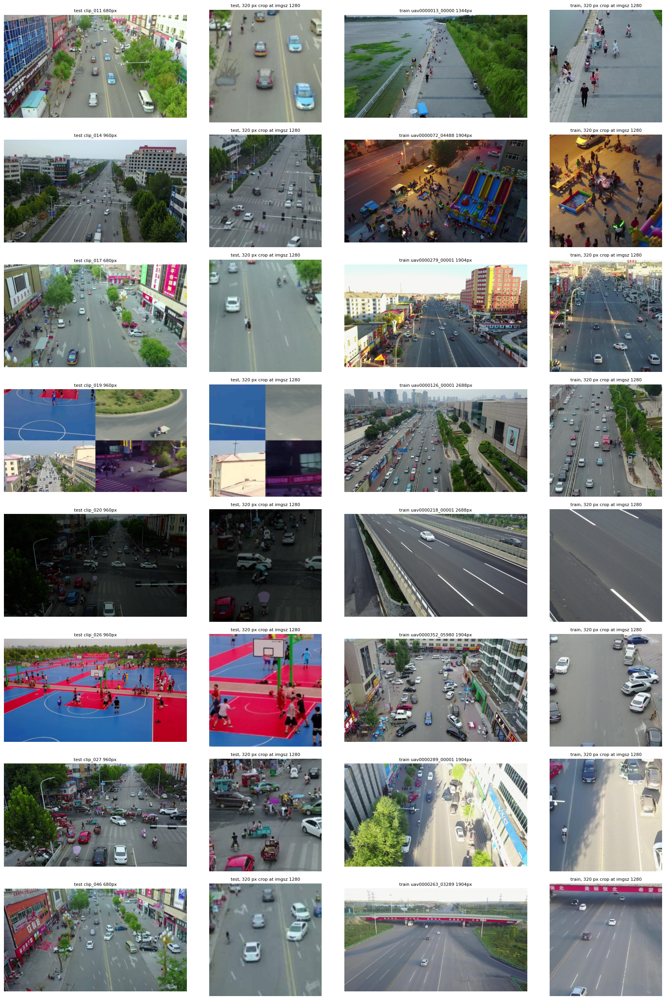

In [14]:
def at_network_input(path, imgsz=1280, crop=320):
    img = Image.open(path).convert("RGB")
    scale = imgsz / max(img.size)
    img = img.resize((round(img.width * scale), round(img.height * scale)), Image.BILINEAR)
    cx, cy = img.width // 2, img.height // 2
    return img, img.crop((cx - crop // 2, cy - crop // 2, cx + crop // 2, cy + crop // 2))


low = look[(look["split"] == "test") & (look["width"] < 1000)].groupby("video").first()
ref = look[(look["split"] == "train")].groupby("video").first().sample(len(low), random_state=SEED) if len(low) else low
fig, axes = plt.subplots(max(len(low), 1), 4, figsize=(18, 3.2 * max(len(low), 1)), squeeze=False)
for row_axes, (vt, t), (vr, r) in zip(axes, low.iterrows(), ref.iterrows()):
    for ax, (title, im) in zip(row_axes, [
        (f"test {vt} {t['width']}px", at_network_input(t["path"])[0]),
        ("test, 320 px crop at imgsz 1280", at_network_input(t["path"])[1]),
        (f"train {vr[:16]} {r['width']}px", at_network_input(r["path"])[0]),
        ("train, 320 px crop at imgsz 1280", at_network_input(r["path"])[1]),
    ]):
        ax.imshow(im)
        ax.set_title(title, fontsize=8)
        ax.axis("off")
plt.tight_layout()
savefig("low_res_test_vs_train")

## Classes


Class counts


split,train,val,train_share,val_share
class,,,,
person,328701,50312,0.297,0.441
bicycle,40255,6022,0.036,0.053
car,505301,31821,0.457,0.279
van,46940,6842,0.042,0.060
truck,30498,1359,0.028,0.012
tricycle,41349,5487,0.037,0.048
bus,9653,264,0.009,0.002
motor,102819,12025,0.093,0.105


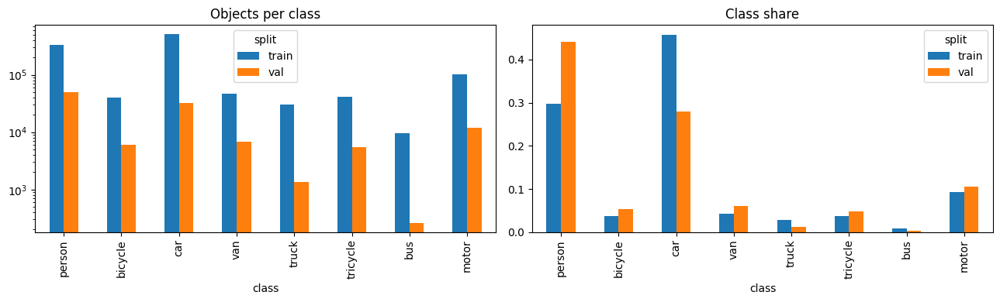

In [15]:
counts = objs.groupby(["class", "split"]).size().unstack().reindex(CLASSES)
share = counts / counts.sum()
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
counts.plot.bar(ax=ax[0], logy=True, title="Objects per class")
share.plot.bar(ax=ax[1], title="Class share")
plt.tight_layout()
savefig("classes")
log("Class counts", counts.assign(train_share=share["train"].round(3), val_share=share["val"].round(3)))

In [16]:
clip_counts = objs.groupby(["video", "class"]).size().unstack(fill_value=0)[CLASSES]
per_clip = clip_counts.div(clip_counts.sum(axis=1), axis=0)
clip_split = images.groupby("video")["split"].first()


def concentration(col):
    s = col.sort_values(ascending=False)
    return pd.Series({
        "clips_with_class": (s > 0).sum(),
        "clips_for_80pct": int((s.cumsum() / s.sum() < 0.8).sum() + 1),
        "top_clip_share": round(s.iloc[0] / s.sum(), 3),
        "val_clips_with_class": (s[clip_split[s.index] == "val"] > 0).sum(),
        "val_objects": s[clip_split[s.index] == "val"].sum(),
    })


log("How concentrated each class is across clips", clip_counts.apply(concentration).T)

train_frames = images[images["split"] == "train"]
present = objs[objs["split"] == "train"].groupby(["image_id", "class"]).size().unstack(fill_value=0) > 0
log("Share of train frames containing each class",
    present.reindex(train_frames["id"], fill_value=False).mean().reindex(CLASSES).round(3))


How concentrated each class is across clips


,clips_with_class,clips_for_80pct,top_clip_share,val_clips_with_class,val_objects
class,,,,,
person,62.0,29.0,0.071,7.0,50312.0
bicycle,46.0,17.0,0.198,5.0,6022.0
car,55.0,26.0,0.080,6.0,31821.0
van,52.0,24.0,0.141,6.0,6842.0
truck,44.0,14.0,0.236,5.0,1359.0
tricycle,44.0,16.0,0.122,5.0,5487.0
bus,25.0,14.0,0.139,1.0,264.0
motor,56.0,21.0,0.141,6.0,12025.0



Share of train frames containing each class


class
person      0.908
bicycle     0.525
car         0.869
van         0.624
truck       0.475
tricycle    0.538
bus         0.274
motor       0.705
dtype: float64

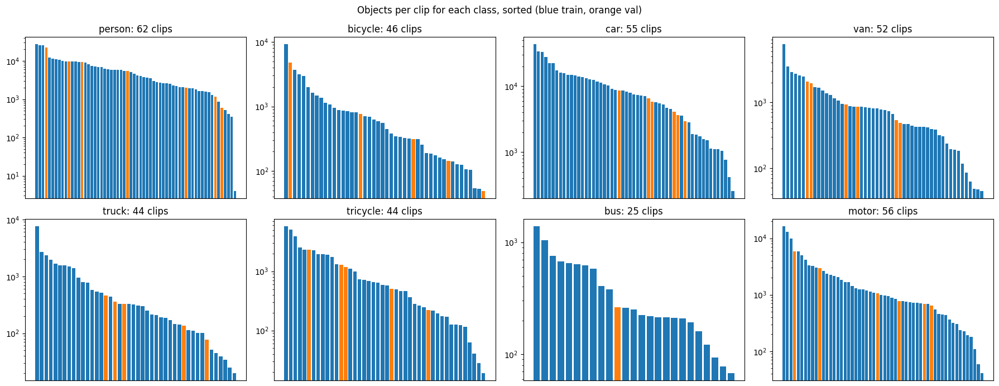

In [17]:
fig, axes = plt.subplots(2, 4, figsize=(18, 7))
for ax, c in zip(axes.flat, CLASSES):
    s = clip_counts[c].sort_values(ascending=False)
    s = s[s > 0]
    ax.bar(range(len(s)), s.values, color=clip_split[s.index].map({"train": "tab:blue", "val": "tab:orange"}))
    ax.set(yscale="log", xticks=[], title=f"{c}: {len(s)} clips")
fig.suptitle("Objects per clip for each class, sorted (blue train, orange val)")
plt.tight_layout()
savefig("class_per_clip")

## Object sizes


Size buckets per class


bucket,small,medium,large
class,,,
person,0.375,0.617,0.007
bicycle,0.216,0.756,0.028
car,0.160,0.649,0.192
van,0.195,0.638,0.167
truck,0.091,0.575,0.334
tricycle,0.208,0.653,0.140
bus,0.040,0.394,0.566
motor,0.314,0.668,0.017



Size buckets overall


bucket
medium    0.640
small     0.244
large     0.116
Name: proportion, dtype: float64


Share of objects below 8 px at network input


640     0.097
1024    0.014
1280    0.006
1536    0.002
dtype: float64

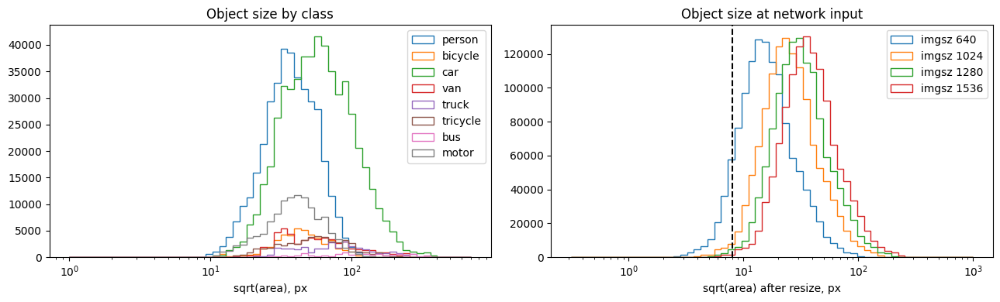

In [18]:
objs["bucket"] = pd.cut(objs["area"], [0, 32 ** 2, 96 ** 2, np.inf], labels=["small", "medium", "large"])
log("Size buckets per class", pd.crosstab(objs["class"], objs["bucket"], normalize="index").reindex(CLASSES).round(3))
log("Size buckets overall", objs["bucket"].value_counts(normalize=True).round(3))

fig, ax = plt.subplots(1, 2, figsize=(13, 4))
bins = np.logspace(0, np.log10(objs["side"].max()), 60)
for c in CLASSES:
    ax[0].hist(objs.loc[objs["class"] == c, "side"], bins=bins, histtype="step", label=c)
ax[0].set(xscale="log", xlabel="sqrt(area), px", title="Object size by class")
ax[0].legend()

long_side = objs[["width", "height"]].max(axis=1)
for imgsz in [640, 1024, 1280, 1536]:
    ax[1].hist(objs["side"] * imgsz / long_side, bins=np.logspace(-0.5, 3, 60), histtype="step", label=f"imgsz {imgsz}")
ax[1].axvline(8, ls="--", c="k")
ax[1].set(xscale="log", xlabel="sqrt(area) after resize, px", title="Object size at network input")
ax[1].legend()
plt.tight_layout()
savefig("object_sizes")

log("Share of objects below 8 px at network input", pd.Series(
    {imgsz: round((objs["side"] * imgsz / long_side < 8).mean(), 3) for imgsz in [640, 1024, 1280, 1536]}))

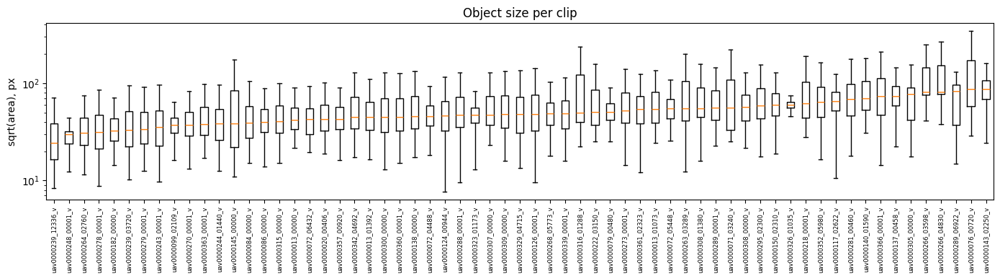

In [19]:
order = objs.groupby("video")["side"].median().sort_values().index
fig, ax = plt.subplots(figsize=(14, 4))
ax.boxplot([objs.loc[objs["video"] == v, "side"] for v in order], showfliers=False)
ax.set_xticks(range(1, len(order) + 1), order, rotation=90, fontsize=6)
ax.set(yscale="log", ylabel="sqrt(area), px", title="Object size per clip")
plt.tight_layout()
savefig("object_size_per_clip")

## Box shapes (k-means at 1280)

In [20]:
wh = objs[["w", "h"]].to_numpy() * 1280 / long_side.to_numpy()[:, None]
km = KMeans(n_clusters=9, n_init=10, random_state=SEED).fit(np.log(wh))
order = np.argsort(km.cluster_centers_.sum(axis=1))
anchor_table = pd.DataFrame(np.exp(km.cluster_centers_[order]), columns=["w", "h"]).round(1)
anchor_table["h/w"] = (anchor_table["h"] / anchor_table["w"]).round(2)
anchor_table["share"] = (np.bincount(km.labels_)[order] / len(wh)).round(3)
log("k-means box shapes at 1280", anchor_table)


k-means box shapes at 1280


,w,h,h/w,share
0,8.9,15.6,1.75,0.066
1,19.1,15.6,0.82,0.098
2,15.3,29.6,1.93,0.157
3,31.3,23.1,0.74,0.159
4,25.7,44.3,1.72,0.166
5,51.5,31.4,0.61,0.138
6,47.4,66.3,1.40,0.099
7,91.6,47.8,0.52,0.075
8,123.8,99.1,0.80,0.043


In [21]:
objs["aspect"] = objs["h"] / objs["w"]
log("Aspect ratio h/w per class", objs.groupby("class")["aspect"].describe().reindex(CLASSES).round(2))


Aspect ratio h/w per class


,count,mean,std,min,25%,50%,75%,max
class,,,,,,,,
person,379013.0,2.01,0.58,0.06,1.64,2.00,2.38,20.00
bicycle,46277.0,1.19,0.58,0.09,0.68,1.08,1.65,7.55
car,537122.0,0.81,0.36,0.04,0.51,0.79,1.02,18.57
van,53782.0,0.92,0.38,0.09,0.60,0.88,1.17,17.22
truck,31857.0,0.90,0.55,0.11,0.55,0.93,1.14,38.75
tricycle,46836.0,1.00,0.38,0.13,0.71,0.95,1.26,4.05
bus,9917.0,0.96,0.55,0.07,0.43,0.96,1.41,11.12
motor,114844.0,1.27,0.55,0.05,0.79,1.24,1.67,17.80


## Objects per frame


Objects per frame


count    27047.0
mean        45.1
std         31.1
min          0.0
25%         21.0
50%         42.0
75%         57.0
max        180.0
Name: n_objects, dtype: float64


Dense frames


'frames with > 100 objects: 0.075, max: 180'

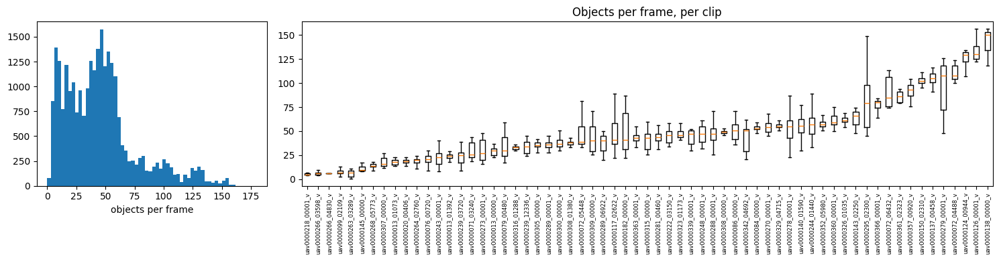

In [22]:
images["n_objects"] = objs.groupby("image_id").size().reindex(images["id"], fill_value=0).to_numpy()
log("Objects per frame", images["n_objects"].describe().round(1))
log("Dense frames", f"frames with > 100 objects: {(images['n_objects'] > 100).mean():.3f}, "
                    f"max: {images['n_objects'].max()}")

order = images.groupby("video")["n_objects"].median().sort_values().index
fig, ax = plt.subplots(1, 2, figsize=(15, 4), gridspec_kw={"width_ratios": [1, 3]})
ax[0].hist(images["n_objects"], bins=60)
ax[0].set(xlabel="objects per frame")
ax[1].boxplot([images.loc[images["video"] == v, "n_objects"] for v in order], showfliers=False)
ax[1].set_xticks(range(1, len(order) + 1), order, rotation=90, fontsize=6)
ax[1].set(title="Objects per frame, per clip")
plt.tight_layout()
savefig("objects_per_frame")

## Occlusion / truncation

In [23]:
log("Occlusion per class", pd.crosstab(objs["class"], objs["occlusion"], normalize="index").reindex(CLASSES).round(3))
log("Truncation per class", pd.crosstab(objs["class"], objs["truncation"], normalize="index").reindex(CLASSES).round(3))


Occlusion per class


occlusion,0.0,1.0,2.0
class,,,
person,0.530,0.409,0.061
bicycle,0.417,0.551,0.032
car,0.562,0.389,0.049
van,0.549,0.415,0.035
truck,0.346,0.498,0.156
tricycle,0.417,0.556,0.026
bus,0.566,0.413,0.020
motor,0.519,0.417,0.064



Truncation per class


truncation,0.0,1.0
class,,
person,0.978,0.022
bicycle,0.990,0.010
car,0.942,0.058
van,0.943,0.057
truck,0.887,0.113
tricycle,0.958,0.042
bus,0.863,0.137
motor,0.967,0.033


## Ignored regions

In [24]:
ignore["frame_share"] = ignore["area"] / (ignore["width"] * ignore["height"])
frame_ignore = ignore.groupby("image_id")["frame_share"].sum().clip(upper=1)
log("Ignored regions", f"frames with ignored regions: {images['id'].isin(frame_ignore.index).mean():.1%}\n"
                       f"ignored share of frame: median {frame_ignore.median():.3f}, max {frame_ignore.max():.3f}")
log("Ignored regions per clip", ignore.groupby("video").size().describe().round(1))


Ignored regions


'frames with ignored regions: 72.2%\nignored share of frame: median 0.131, max 1.000'


Ignored regions per clip


count       55.0
mean      9867.3
std       9865.6
min        736.0
25%       2996.0
50%       6584.0
75%      13404.0
max      53992.0
dtype: float64

In [25]:
def overlap_with_ignore(objs, ignore):
    out = pd.Series(0.0, index=objs.index)
    ign = ignore.groupby("image_id")[["x", "y", "w", "h"]].apply(lambda g: g.to_numpy())
    for image_id, group in objs[objs["image_id"].isin(ign.index)].groupby("image_id"):
        o, r = group[["x", "y", "w", "h"]].to_numpy(), ign[image_id]
        ix = np.clip(np.minimum(o[:, None, 0] + o[:, None, 2], r[None, :, 0] + r[None, :, 2])
                     - np.maximum(o[:, None, 0], r[None, :, 0]), 0, None)
        iy = np.clip(np.minimum(o[:, None, 1] + o[:, None, 3], r[None, :, 1] + r[None, :, 3])
                     - np.maximum(o[:, None, 1], r[None, :, 1]), 0, None)
        out[group.index] = np.clip((ix * iy).sum(axis=1) / (o[:, 2] * o[:, 3]), 0, 1)
    return out


objs["ignore_overlap"] = overlap_with_ignore(objs, ignore)
log("Objects inside ignored regions", f"objects >= 50% inside: {(objs['ignore_overlap'] >= 0.5).mean():.2%}\n"
                                      f"objects touching one: {(objs['ignore_overlap'] > 0).mean():.2%}")


Objects inside ignored regions


'objects >= 50% inside: 2.73%\nobjects touching one: 3.49%'

## What the ignored regions are


Ignored annotations by original category


kind,ignored region,others
split,,
train,498952,11792
val,31952,8



Size of ignored annotations vs objects (sqrt area, px)


,count,mean,std,min,25%,50%,75%,max
ignored region,530904.0,121.3,92.9,12.4,62.9,94.0,150.3,678.9
others,11800.0,134.5,96.9,22.0,37.3,82.6,239.5,329.7
objects,1219648.0,57.1,38.9,7.7,32.3,46.4,68.8,703.0



Ignored annotations per frame


count    27047.0
mean        20.1
std         24.9
min          0.0
25%          0.0
50%          8.0
75%         32.0
max        176.0
dtype: float64


Frames by ignored share of area


frame_share
(-0.01, 0.0]    7523
(0.0, 0.05]     3495
(0.05, 0.15]    7161
(0.15, 0.3]     3932
(0.3, 0.5]      2400
(0.5, 1.0]      2536
Name: count, dtype: int64

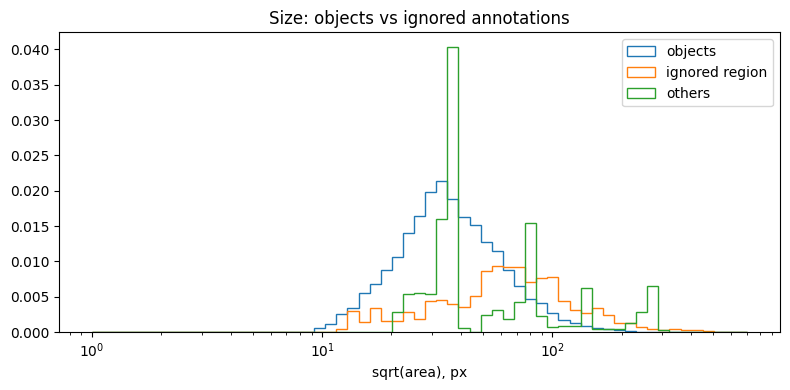

In [26]:
# VisDrone original ids: 0 = ignored region, 11 = others
ignore["kind"] = (ignore.reindex(columns=["orig_category_id"])["orig_category_id"]
                  .map({0: "ignored region", 11: "others"}).fillna("unknown"))
ignore["side"] = np.sqrt(ignore["area"])
log("Ignored annotations by original category", ignore.groupby(["split", "kind"]).size().unstack(fill_value=0))
log("Size of ignored annotations vs objects (sqrt area, px)", pd.concat(
    [ignore.groupby("kind")["side"].describe(), objs["side"].describe().to_frame("objects").T]).round(1))
log("Ignored annotations per frame", ignore.groupby("image_id").size()
    .reindex(images["id"], fill_value=0).describe().round(1))
log("Frames by ignored share of area", pd.cut(frame_ignore.reindex(images["id"], fill_value=0),
                                              [-0.01, 0, 0.05, 0.15, 0.3, 0.5, 1.0]).value_counts().sort_index())

fig, ax = plt.subplots(figsize=(8, 4))
bins = np.logspace(0, np.log10(max(ignore["side"].max(), objs["side"].max())), 60)
ax.hist(objs["side"], bins=bins, histtype="step", density=True, label="objects")
for kind, g in ignore.groupby("kind"):
    ax.hist(g["side"], bins=bins, histtype="step", density=True, label=kind)
ax.set(xscale="log", xlabel="sqrt(area), px", title="Size: objects vs ignored annotations")
ax.legend()
plt.tight_layout()
savefig("ignore_sizes")

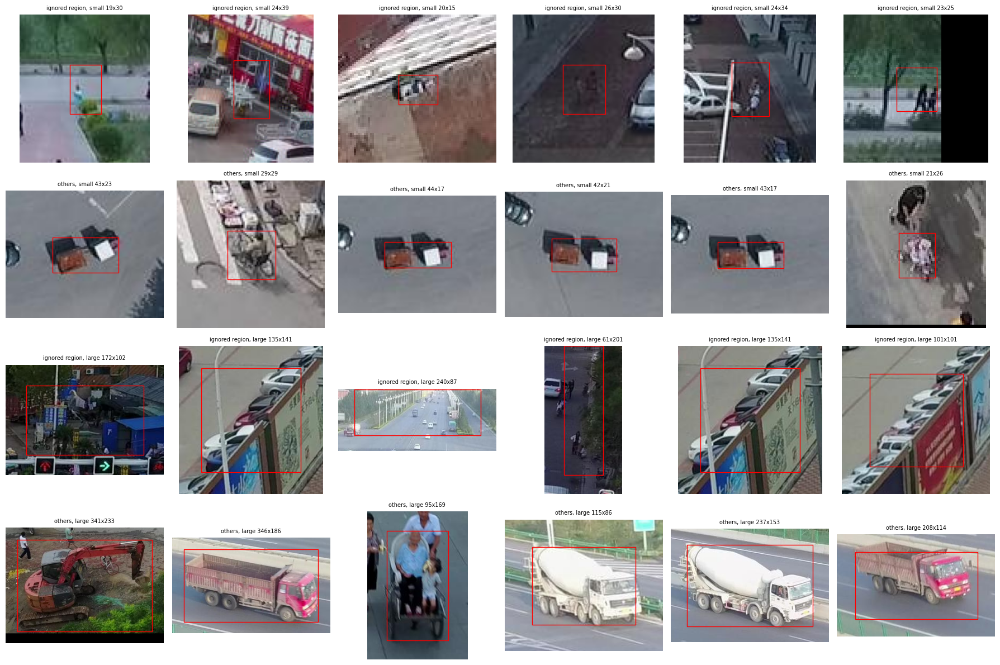

In [27]:
groups = [(f"{kind}, small", g[g["side"] < 32]) for kind, g in ignore.groupby("kind")] + \
         [(f"{kind}, large", g[g["side"] >= 96]) for kind, g in ignore.groupby("kind")]
groups = [(name, g) for name, g in groups if len(g)]
fig, axes = plt.subplots(len(groups), 6, figsize=(18, 3 * len(groups)), squeeze=False)
for row_axes, (name, g) in zip(axes, groups):
    for ax, (_, a) in zip(row_axes, g.sample(min(6, len(g)), random_state=SEED).iterrows()):
        show_crop(ax, a, f"{name} {a['w']:.0f}x{a['h']:.0f}", pad=30, color="red")
plt.tight_layout()
savefig("ignore_crops")

## Same-track IoU between frame t and t+k


Same-track IoU vs frame step


,step,median_iou,share_iou_gt_0.7
0,1,0.895,0.854
1,2,0.806,0.664
2,3,0.727,0.534
3,5,0.591,0.391
4,10,0.348,0.252
5,15,0.194,0.200
6,20,0.093,0.172
7,30,0.000,0.142


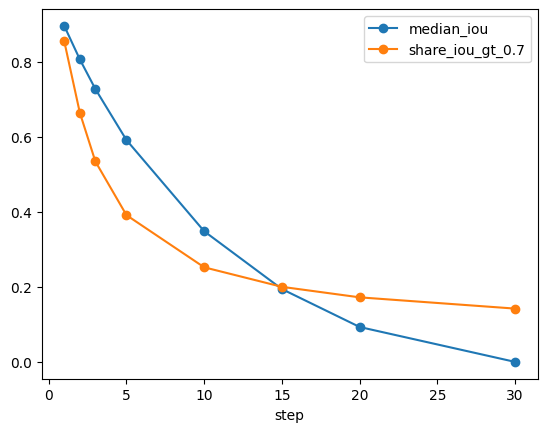

In [28]:
def box_iou(a, b):
    ix = np.clip(np.minimum(a[:, 0] + a[:, 2], b[:, 0] + b[:, 2]) - np.maximum(a[:, 0], b[:, 0]), 0, None)
    iy = np.clip(np.minimum(a[:, 1] + a[:, 3], b[:, 1] + b[:, 3]) - np.maximum(a[:, 1], b[:, 1]), 0, None)
    inter = ix * iy
    return inter / (a[:, 2] * a[:, 3] + b[:, 2] * b[:, 3] - inter)


tracks = objs.dropna(subset=["track_id"])[["video", "track_id", "frame_id", "x", "y", "w", "h"]]
rows = []
for k in [1, 2, 3, 5, 10, 15, 20, 30]:
    nxt = tracks.assign(frame_id=tracks["frame_id"] - k)
    m = tracks.merge(nxt, on=["video", "track_id", "frame_id"], suffixes=("", "_k"))
    iou = box_iou(m[["x", "y", "w", "h"]].to_numpy(), m[["x_k", "y_k", "w_k", "h_k"]].to_numpy())
    rows.append({"step": k, "median_iou": np.median(iou), "share_iou_gt_0.7": (iou > 0.7).mean()})
redundancy = pd.DataFrame(rows).round(3)
redundancy.plot(x="step", marker="o")
savefig("track_iou_vs_step")
log("Same-track IoU vs frame step", redundancy)

## GT on sample frames (green — objects, red — ignored)

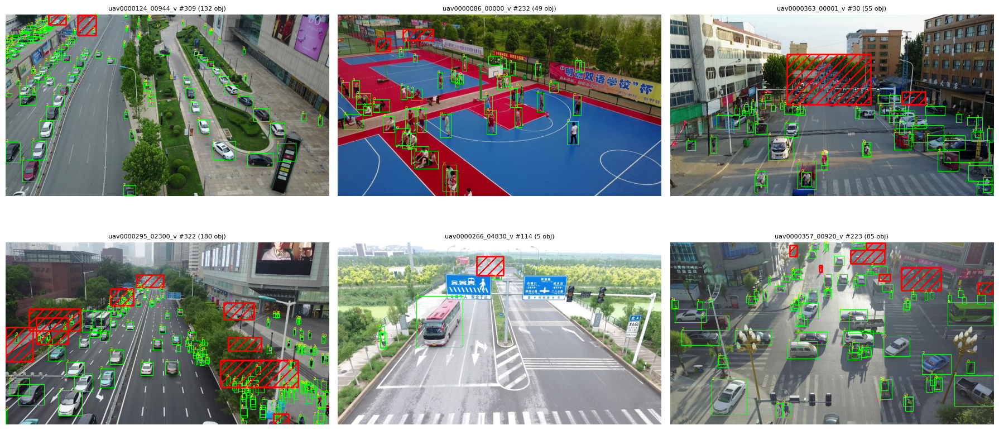

In [29]:
def show_frame(row, ax):
    ax.imshow(Image.open(frame_path(row)))
    for o in objs[objs["image_id"] == row["id"]].itertuples():
        ax.add_patch(Rectangle((o.x, o.y), o.w, o.h, fill=False, ec="lime", lw=0.8))
        ax.text(o.x, o.y, o.cls, color="yellow", fontsize=5)
    for r in ignore[ignore["image_id"] == row["id"]].itertuples():
        ax.add_patch(Rectangle((r.x, r.y), r.w, r.h, fill=False, ec="red", hatch="//", lw=1))
    ax.set_title(f"{row['video']} #{row['frame_id']} ({row['n_objects']} obj)", fontsize=8)
    ax.axis("off")


sample = images[images["id"].isin(ignore["image_id"])].sample(3, random_state=SEED)
sample = pd.concat([sample, images.nlargest(1, "n_objects"), images.sample(2, random_state=SEED)])
fig, axes = plt.subplots(2, 3, figsize=(18, 9))
for (_, row), ax in zip(sample.iterrows(), axes.flat):
    show_frame(row, ax)
plt.tight_layout()
savefig("gt_samples")

## Per-clip table

In [30]:
clip_stats = images.groupby("video").agg(split=("split", "first"), frames=("id", "size"),
                                         width=("width", "first"), height=("height", "first"),
                                         objects_median=("n_objects", "median"), objects_max=("n_objects", "max"))
clip_stats["size_median"] = objs.groupby("video")["side"].median().round(1)
clip_stats["small_share"] = objs.groupby("video")["bucket"].apply(lambda b: (b == "small").mean()).round(3)
clip_stats["ignore_share"] = ignore.groupby("video")["frame_share"].sum().div(clip_stats["frames"]).round(3)
clip_stats = clip_stats.join(clip_look.set_index("video")[["brightness", "contrast", "dark_share"]].round(2))
clip_stats = clip_stats.join(per_clip.round(3).add_prefix("share_"))
clip_stats.to_csv(EDA_OUT / "clip_stats.csv")
clip_look[clip_look["split"] == "test"].to_csv(EDA_OUT / "test_clip_look.csv", index=False)
clip_stats.head()

,split,frames,width,height,objects_median,objects_max,size_median,small_share,ignore_share,brightness,contrast,dark_share,share_person,share_bicycle,share_car,share_van,share_truck,share_tricycle,share_bus,share_motor
video,,,,,,,,,,,,,,,,,,,,
uav0000013_00000_v,train,269,1344,756,30.0,37,41.7,0.211,0.297,96.29,38.01,0.11,0.742,0.016,0.000,0.000,0.0,0.028,0.0,0.214
uav0000013_01073_v,train,58,1344,756,18.0,23,54.3,0.105,0.290,97.38,35.04,0.09,0.827,0.000,0.000,0.000,0.0,0.000,0.0,0.173
uav0000013_01392_v,train,118,1344,756,24.0,29,44.8,0.227,0.285,94.98,38.16,0.15,0.676,0.000,0.000,0.000,0.0,0.061,0.0,0.263
uav0000020_00406_v,train,501,1344,756,19.0,23,42.7,0.229,0.104,109.38,45.03,0.11,0.793,0.033,0.000,0.000,0.0,0.039,0.0,0.134
uav0000071_03240_v,train,181,1904,1071,26.0,44,56.3,0.196,0.539,57.91,37.62,0.55,0.481,0.047,0.337,0.012,0.0,0.021,0.0,0.102


## Splits by source video
Clip names look like `uav0000013_01073_v`: several clips can be segments of one source video.

In [31]:
images["source"] = images["video"].str.split("_").str[0]
by_source = images.groupby("source").agg(clips=("video", "nunique"), splits=("split", lambda s: sorted(set(s))))
log("Clips per source video", by_source["clips"].value_counts().sort_index().rename("source videos"))
shared = by_source[by_source["splits"].str.len() > 1]
log("Source videos present in both train and val", shared if len(shared) else "none")

test_sources = set(test["file_name"].str.extract(r"(uav\d+)")[0].dropna())
log("Test clips", "test clip names are anonymised (clip_001 ...), so overlap with train cannot be checked"
    if not test_sources else f"test source videos also in train: {sorted(test_sources & set(images['source']))}")


Clips per source video


clips
1    49
2     4
3     2
Name: source videos, dtype: int64


Source videos present in both train and val


'none'


Test clips


'test clip names are anonymised (clip_001 ...), so overlap with train cannot be checked'

In [32]:
images["fold"] = -1
for fold, (_, idx) in enumerate(GroupKFold(n_splits=5).split(images, groups=images["source"])):
    images.loc[images.index[idx], "fold"] = fold
clips = images.groupby("video").agg(source=("source", "first"), split=("split", "first"), fold=("fold", "first"),
                                    frames=("id", "size")).reset_index()
assert clips.groupby("source")["fold"].nunique().max() == 1, "a source video is split across folds"
clips.to_csv(OUT / "folds.csv", index=False)
log("Folds (grouped by source video)", clips.groupby("fold").agg(
    sources=("source", "nunique"), clips=("video", "size"), frames=("frames", "sum")))


Folds (grouped by source video)


,sources,clips,frames
fold,,,
0,11,12,5422
1,11,14,5407
2,11,12,5407
3,11,13,5404
4,11,12,5407


## Preprocessing: what the models are trained on
Ultralytics reads the provided YOLO txt labels; torchvision models read `vod.data.load_split`
(COCO json → pixel xyxy, classes 0-7 → labels 1-8, ignored regions kept separately).

In [33]:
from vod.data import load_split, object_bank, repeat_factors
from vod.tv import FrameDataset, covered_share

PREP = dict(imgsz=1280, mask_ignore=True, hflip=0.5, color_p=0.5, degrade_p=0.3,
            paste_p=0.5, paste_max=3, paste_classes=[1, 3, 4, 5, 6], rfs_t=0.5, seed=SEED)
prep_frames, prep_targets = load_split(DATA / "val", step=50)


def yolo_boxes(img_path, w, h):
    p = Path(img_path)
    label = p.parents[2] / "labels" / p.parent.name / f"{p.stem}.txt"
    if not label.exists() or label.stat().st_size == 0:
        return np.zeros((0, 5))
    a = np.loadtxt(label, ndmin=2)
    cx, cy, bw, bh = a[:, 1] * w, a[:, 2] * h, a[:, 3] * w, a[:, 4] * h
    return np.column_stack([a[:, 0], cx - bw / 2, cy - bh / 2, cx + bw / 2, cy + bh / 2])


# YOLO txt and COCO json should describe the same boxes
diffs = []
for _, r in prep_frames.iterrows():
    yb = yolo_boxes(r["path"], r["width"], r["height"])
    cb, cc, _ = prep_targets[r["id"]]
    if len(yb) != len(cb):
        diffs.append({"frame": r["path"], "yolo": len(yb), "coco": len(cb)})
        continue
    co = np.column_stack([cc, cb])
    yb = yb[np.lexsort(np.round(yb[:, :3]).T[::-1])]
    co = co[np.lexsort(np.round(co[:, :3]).T[::-1])]
    diffs.append({"frame": r["path"], "yolo": len(yb), "coco": len(cb),
                  "class_mismatch": int((yb[:, 0] != co[:, 0]).sum()),
                  "max_px_diff": float(np.abs(yb[:, 1:] - co[:, 1:]).max()) if len(yb) else 0.0})
diffs = pd.DataFrame(diffs)
log("YOLO txt vs COCO json on sampled val frames", diffs.drop(columns="frame").describe().round(2))


YOLO txt vs COCO json on sampled val frames


,yolo,coco,class_mismatch,max_px_diff
count,60.00,60.00,60.0,60.0
mean,40.40,40.40,0.0,0.0
std,27.91,27.91,0.0,0.0
min,8.00,8.00,0.0,0.0
25%,15.75,15.75,0.0,0.0
50%,37.00,37.00,0.0,0.0
75%,51.50,51.50,0.0,0.0
max,111.00,111.00,0.0,0.0


## Rare classes: repeat-factor sampling and copy-paste (built from train only)

In [34]:
train_frames, train_targets = load_split(DATA / "train", step=5)
weights, r_cls = repeat_factors(train_frames, train_targets, PREP["rfs_t"])
present = pd.DataFrame([{c: c in set(train_targets[i][1].tolist()) for c in range(len(CLASSES))}
                        for i in train_frames["id"]])
objects = pd.DataFrame([np.bincount(train_targets[i][1], minlength=len(CLASSES)) for i in train_frames["id"]])
log("Effect of repeat-factor sampling on what the model sees per epoch", pd.DataFrame({
    "repeat_factor": r_cls.reindex(range(len(CLASSES))).round(2).to_numpy(),
    "frame_share": present.mean().round(3).to_numpy(),
    "frame_share_rfs": (present.mul(weights, axis=0).sum() / weights.sum()).round(3).to_numpy(),
    "object_share": (objects.sum() / objects.sum().sum()).round(4).to_numpy(),
    "object_share_rfs": (objects.mul(weights, axis=0).sum() / objects.mul(weights, axis=0).sum().sum()).round(4).to_numpy(),
}, index=CLASSES))

bank = object_bank(DATA / "train", PREP["paste_classes"], step=5)
log("Copy-paste bank (clean train objects, min side 12 px)",
    bank["cls"].map(dict(enumerate(CLASSES))).value_counts())


Effect of repeat-factor sampling on what the model sees per epoch


,repeat_factor,frame_share,frame_share_rfs,object_share,object_share_rfs
person,1.00,0.908,0.901,0.2977,0.2872
bicycle,1.00,0.526,0.530,0.0365,0.0362
car,1.00,0.869,0.880,0.4568,0.4657
van,1.00,0.624,0.640,0.0424,0.0447
truck,1.03,0.475,0.496,0.0275,0.0285
tricycle,1.00,0.539,0.539,0.0374,0.0369
bus,1.35,0.274,0.335,0.0087,0.0105
motor,1.00,0.706,0.712,0.0929,0.0903



Copy-paste bank (clean train objects, min side 12 px)


cls
van         5106
bicycle     3586
tricycle    3210
truck       1919
bus          964
Name: count, dtype: int64


Objects dropped because >= 50% inside a masked region


'30 of 155 in this frame'


Preprocessing config


{'imgsz': 1280,
 'mask_ignore': True,
 'hflip': 0.5,
 'color_p': 0.5,
 'degrade_p': 0.3,
 'paste_p': 0.5,
 'paste_max': 3,
 'paste_classes': [1, 3, 4, 5, 6],
 'rfs_t': 0.5,
 'seed': 42}

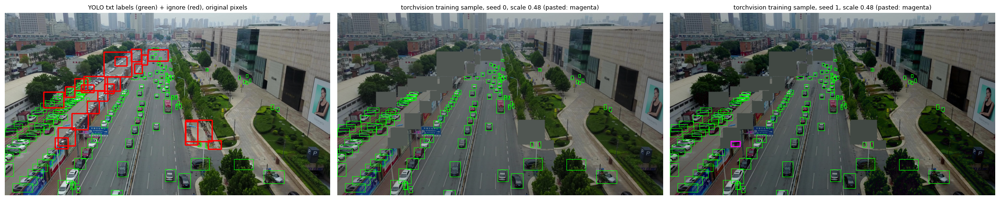

In [35]:
# The same frame as each framework receives it: YOLO txt labels, then the torchvision training sample
# (resized, ignored regions greyed out, rare objects pasted, augmented) for two seeds
r = train_frames.loc[train_frames["id"].map(lambda i: len(train_targets[i][2])).idxmax()]
ds = FrameDataset(train_frames[train_frames["id"] == r["id"]], train_targets, PREP, train=True, bank=bank)
kept_boxes, _, kept_ignore = train_targets[r["id"]]
pasted_from = int((covered_share(kept_boxes, kept_ignore) <= 0.5).sum())
log("Objects dropped because >= 50% inside a masked region",
    f"{len(kept_boxes) - pasted_from} of {len(kept_boxes)} in this frame")

fig, axes = plt.subplots(1, 3, figsize=(21, 5))
axes[0].imshow(Image.open(r["path"]))
for c, x1, y1, x2, y2 in yolo_boxes(r["path"], r["width"], r["height"]):
    axes[0].add_patch(Rectangle((x1, y1), x2 - x1, y2 - y1, fill=False, ec="lime", lw=0.7))
for x1, y1, x2, y2 in train_targets[r["id"]][2]:
    axes[0].add_patch(Rectangle((x1, y1), x2 - x1, y2 - y1, fill=False, ec="red", lw=1))
axes[0].set_title("YOLO txt labels (green) + ignore (red), original pixels", fontsize=9)
for ax, seed in zip(axes[1:], [0, 1]):
    random.seed(seed)
    img, target, meta = ds[0]
    ax.imshow(img.permute(1, 2, 0).numpy())
    for k, (x1, y1, x2, y2) in enumerate(target["boxes"].numpy()):
        pasted = k >= pasted_from
        ax.add_patch(Rectangle((x1, y1), x2 - x1, y2 - y1, fill=False, ec="magenta" if pasted else "lime",
                               lw=1.5 if pasted else 0.7))
    ax.set_title(f"torchvision training sample, seed {seed}, scale {meta['scale']:.2f} (pasted: magenta)",
                 fontsize=9)
for ax in axes:
    ax.axis("off")
plt.tight_layout()
savefig("preprocessing_check")
log("Preprocessing config", PREP)

In [36]:
(EDA_OUT / "eda_summary.md").write_text("# EDA summary\n\n" + "\n".join(summary))
sorted(p.name for p in EDA_OUT.iterdir())

['brightening_options.png',
 'brightness_hist.png',
 'brightness_per_clip.png',
 'class_per_clip.png',
 'classes.png',
 'clip_stats.csv',
 'clip_thumbnails.png',
 'eda_summary.md',
 'gt_samples.png',
 'ignore_crops.png',
 'ignore_sizes.png',
 'low_res_test_vs_train.png',
 'object_size_per_clip.png',
 'object_sizes.png',
 'objects_per_frame.png',
 'odd_aspect_boxes.png',
 'preprocessing_check.png',
 'test_clip_look.csv',
 'track_iou_vs_step.png']

## Observations